# Hospital Appointment & No-Show Analysis

### Understanding appointment attendance, scheduling lead time, reminder coverage, and operational risk

**Project type:** Exploratory Data Analysis / Healthcare Operations Analytics  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SQLite, Jupyter Notebook

## Business objective

Missed appointments reduce clinical capacity and can delay access to care. This project analyzes appointment-level data to identify **observable patterns associated with missed appointments** and translate them into practical operational recommendations.

The analysis focuses on:
1. Overall no-show burden.
2. Patient and appointment characteristics associated with different no-show rates.
3. The relationship between scheduling lead time and attendance.
4. SMS reminder patterns, interpreted in context rather than as causal evidence.
5. Operational actions that could be tested to improve appointment utilization.

> **Analytical caution:** This is observational data. The analysis identifies associations and patterns; it does not establish that a characteristic causes a patient to miss an appointment.

## Dataset

The supplied dataset contains **110,527 appointment records** and 14 original variables covering patient demographics, appointment timing, selected health indicators, SMS reminders, and appointment outcome.

The raw CSV is stored at `data/Medical Appointment No Shows.csv`.

| Field | Business meaning |
|---|---|
| `PatientId` | Patient identifier |
| `AppointmentID` | Appointment identifier |
| `Gender` | Patient gender |
| `ScheduledDay` | Date/time when appointment was scheduled |
| `AppointmentDay` | Appointment date |
| `Age` | Patient age |
| `Neighbourhood` | Appointment neighbourhood |
| `Scholarship` | Government assistance indicator |
| `Hipertension` | Hypertension indicator in source data |
| `Diabetes` | Diabetes indicator |
| `Alcoholism` | Alcoholism indicator |
| `Handcap` | Handicap indicator in source data |
| `SMS_received` | Whether an SMS reminder was received |
| `No-show` | Appointment outcome |

In [1]:
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_PATH = "data/Medical Appointment No Shows.csv"
SQLITE_PATH = "hospital_appointments.sqlite"

df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
display(df_raw.head())

Shape: (110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,"29,872,499,824,296.00",5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,"558,997,776,694,438.00",5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,"4,262,962,299,951.00",5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,"867,951,213,174.00",5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,"8,841,186,448,183.00",5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


## 1. Data Quality Audit

In [2]:
audit = pd.DataFrame({
    "Metric": [
        "Rows", "Columns", "Unique patients", "Unique appointments",
        "Duplicate rows", "Missing cells"
    ],
    "Value": [
        len(df_raw), df_raw.shape[1], df_raw["PatientId"].nunique(),
        df_raw["AppointmentID"].nunique(), df_raw.duplicated().sum(),
        int(df_raw.isna().sum().sum())
    ]
})
display(audit)
display(df_raw.dtypes.to_frame("dtype"))
display(df_raw.isna().sum().to_frame("missing_values"))

,Metric,Value
0,Rows,110527
1,Columns,14
2,Unique patients,62299
3,Unique appointments,110527
4,Duplicate rows,0
5,Missing cells,0


,dtype
PatientId,float64
AppointmentID,int64
Gender,str
ScheduledDay,str
AppointmentDay,str
Age,int64
Neighbourhood,str
Scholarship,int64
Hipertension,int64
Diabetes,int64


,missing_values
PatientId,0
AppointmentID,0
Gender,0
ScheduledDay,0
AppointmentDay,0
Age,0
Neighbourhood,0
Scholarship,0
Hipertension,0
Diabetes,0


### Data-quality observations

- There are no missing cells in the supplied dataset.
- `AppointmentID` is unique.
- No duplicate rows were found.
- One record contains `Age = -1`, which is not a valid age and will be treated as missing.
- Five records produce a negative scheduling lead time after date conversion. They are retained for audit transparency but excluded from lead-time analysis.
- The source spelling of fields such as `Hipertension` and `Handcap` is preserved in the raw data.

## 2. Data Cleaning & Feature Engineering

In [3]:
df = df_raw.copy()

df["ScheduledDay"] = pd.to_datetime(df["ScheduledDay"], errors="coerce", utc=True)
df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"], errors="coerce", utc=True)

df["Age_clean"] = df["Age"].replace(-1, np.nan)

df["no_show"] = df["No-show"].eq("Yes")
df["showed"] = df["No-show"].eq("No")

df["waiting_days"] = (
    df["AppointmentDay"].dt.normalize() -
    df["ScheduledDay"].dt.normalize()
).dt.days

df["appointment_weekday"] = df["AppointmentDay"].dt.day_name()
df["appointment_month"] = df["AppointmentDay"].dt.to_period("M").astype(str)

age_bins = [0, 12, 17, 24, 34, 44, 54, 64, 74, np.inf]
age_labels = ["0–12", "13–17", "18–24", "25–34", "35–44",
              "45–54", "55–64", "65–74", "75+"]
df["age_group"] = pd.cut(
    df["Age_clean"], bins=age_bins, labels=age_labels, include_lowest=True
)

lead_bins = [-np.inf, 0, 2, 7, 14, 30, 60, 90, np.inf]
lead_labels = ["Same day", "1–2 days", "3–7 days", "8–14 days",
               "15–30 days", "31–60 days", "61–90 days", "90+ days"]
df["lead_time_band"] = pd.cut(
    df["waiting_days"], bins=lead_bins, labels=lead_labels
)

df["patient_appointment_number"] = (
    df.sort_values(["PatientId", "AppointmentDay", "AppointmentID"])
      .groupby("PatientId").cumcount() + 1
)
df["patient_total_appointments"] = df.groupby("PatientId")["AppointmentID"].transform("count")
df["repeat_patient"] = df["patient_total_appointments"].gt(1)
df["condition_count"] = df[["Scholarship", "Hipertension", "Diabetes", "Alcoholism"]].sum(axis=1)

negative_waiting = df[df["waiting_days"] < 0].copy()
df_analysis = df[df["waiting_days"] >= 0].copy()

cleaning_summary = pd.DataFrame({
    "Metric": [
        "Rows in raw data", "Rows used for main analysis",
        "Invalid ages corrected", "Negative lead-time records",
        "Missing cells after cleaning", "Duplicate rows"
    ],
    "Value": [
        len(df_raw), len(df_analysis), int(df_raw["Age"].eq(-1).sum()),
        len(negative_waiting), int(df.isna().sum().sum()),
        int(df.duplicated().sum())
    ]
})
display(cleaning_summary)

,Metric,Value
0,Rows in raw data,110527
1,Rows used for main analysis,110522
2,Invalid ages corrected,1
3,Negative lead-time records,5
4,Missing cells after cleaning,2
5,Duplicate rows,0


## 3. Executive KPI Snapshot

The first goal is to establish the operational scale before investigating individual segments.

In [4]:
total_appointments = len(df_analysis)
unique_patients = df_analysis["PatientId"].nunique()
no_show_count = int(df_analysis["no_show"].sum())
showed_count = int(df_analysis["showed"].sum())
no_show_rate = df_analysis["no_show"].mean()
sms_coverage = df_analysis["SMS_received"].mean()
repeat_patient_share = df_analysis["repeat_patient"].mean()
median_wait = df_analysis["waiting_days"].median()

kpis = pd.DataFrame({
    "KPI": [
        "Appointments analysed", "Unique patients", "Completed appointments",
        "No-show appointments", "No-show rate", "Attendance rate",
        "SMS coverage", "Repeat-patient appointment share",
        "Median scheduling lead time (days)"
    ],
    "Value": [
        f"{total_appointments:,}", f"{unique_patients:,}", f"{showed_count:,}",
        f"{no_show_count:,}", f"{no_show_rate:.1%}", f"{1-no_show_rate:.1%}",
        f"{sms_coverage:.1%}", f"{repeat_patient_share:.1%}", f"{median_wait:.0f}"
    ]
})
display(kpis)

,KPI,Value
0,Appointments analysed,"110,522"
1,Unique patients,"62,299"
2,Completed appointments,"88,208"
3,No-show appointments,"22,314"
4,No-show rate,20.2%
5,Attendance rate,79.8%
6,SMS coverage,32.1%
7,Repeat-patient appointment share,65.7%
8,Median scheduling lead time (days),4


## 4. Appointment Outcome Profile

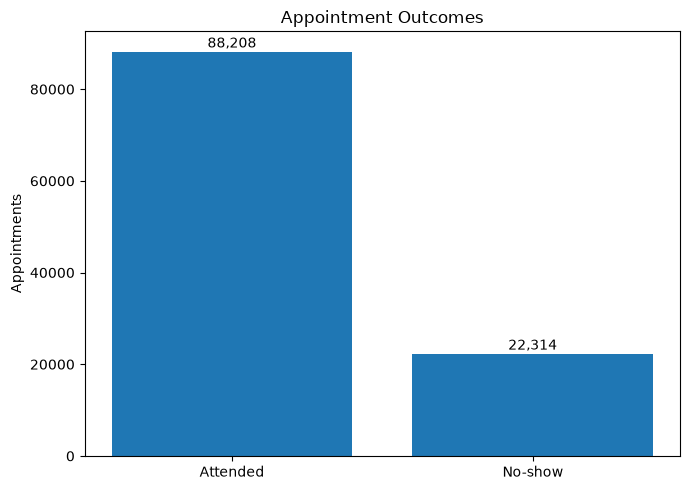

In [5]:
outcome = df_analysis["No-show"].value_counts().reindex(["No", "Yes"])

plt.figure(figsize=(7, 5))
plt.bar(["Attended", "No-show"], outcome.values)
plt.title("Appointment Outcomes")
plt.ylabel("Appointments")
for i, value in enumerate(outcome.values):
    plt.text(i, value + outcome.max()*0.01, f"{value:,}", ha="center")
plt.tight_layout()
plt.show()

## 5. Scheduling Lead Time

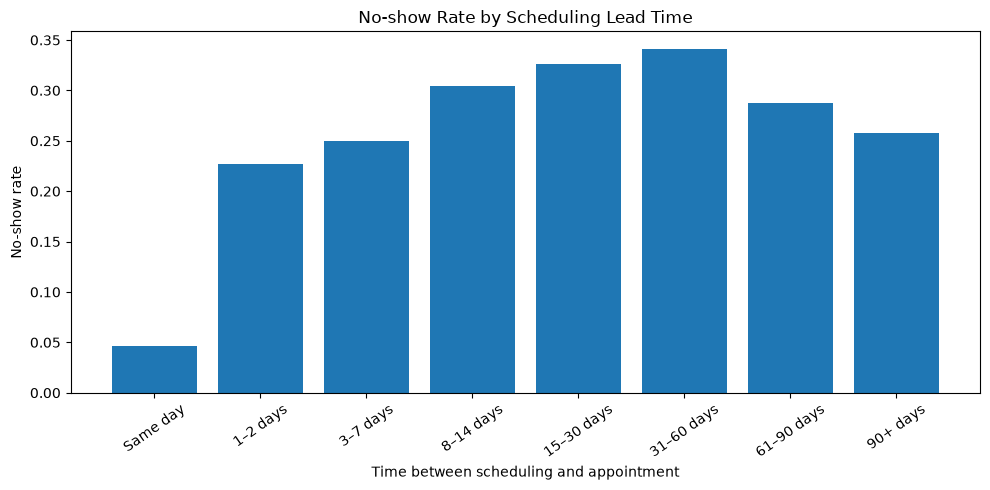

,lead_time_band,appointments,no_show_rate
0,Same day,38563,4.6%
1,1–2 days,11938,22.7%
2,3–7 days,20247,25.0%
3,8–14 days,12025,30.5%
4,15–30 days,17371,32.6%
5,31–60 days,8283,34.2%
6,61–90 days,1878,28.8%
7,90+ days,217,25.8%


In [6]:
lead_summary = (
    df_analysis.groupby("lead_time_band", observed=False)
    .agg(appointments=("AppointmentID", "size"),
         no_show_rate=("no_show", "mean"))
    .reset_index()
)

plt.figure(figsize=(10, 5))
plt.bar(lead_summary["lead_time_band"].astype(str), lead_summary["no_show_rate"])
plt.title("No-show Rate by Scheduling Lead Time")
plt.xlabel("Time between scheduling and appointment")
plt.ylabel("No-show rate")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

display(lead_summary.assign(
    no_show_rate=lead_summary["no_show_rate"].map(lambda x: f"{x:.1%}")
))

**Finding:** Same-day appointments have a much lower observed no-show rate, while several multi-week lead-time bands have substantially higher rates. This makes lead time an important operational segmentation variable.

This is an association, not proof that waiting time itself causes missed appointments.

## 6. Appointment Day & Month

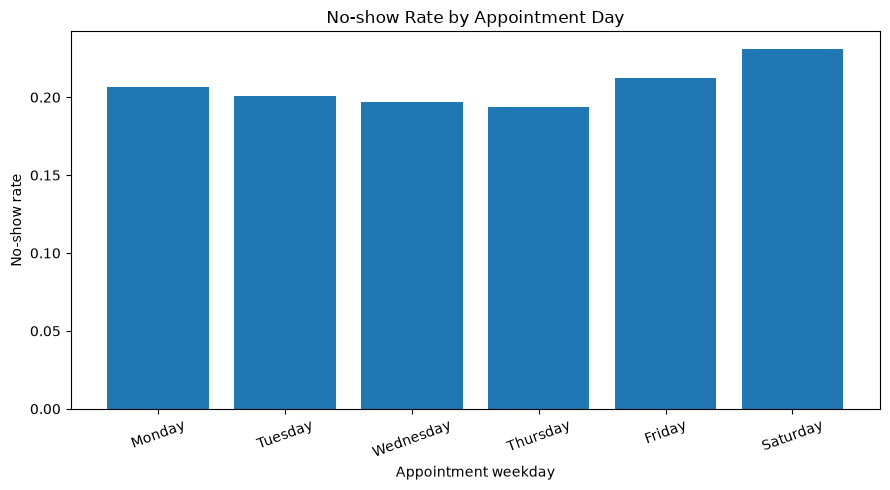

,appointment_weekday,appointments,no_show_rate
0,Monday,22714,20.6%
1,Tuesday,25638,20.1%
2,Wednesday,25866,19.7%
3,Thursday,17246,19.3%
4,Friday,19019,21.2%
5,Saturday,39,23.1%


In [7]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]

weekday_summary = (
    df_analysis.groupby("appointment_weekday")
    .agg(appointments=("AppointmentID", "size"),
         no_show_rate=("no_show", "mean"))
    .reindex(weekday_order)
    .reset_index()
)

plt.figure(figsize=(9, 5))
plt.bar(weekday_summary["appointment_weekday"].astype(str), weekday_summary["no_show_rate"])
plt.title("No-show Rate by Appointment Day")
plt.xlabel("Appointment weekday")
plt.ylabel("No-show rate")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

display(weekday_summary.assign(
    no_show_rate=weekday_summary["no_show_rate"].map(lambda x: f"{x:.1%}")
))

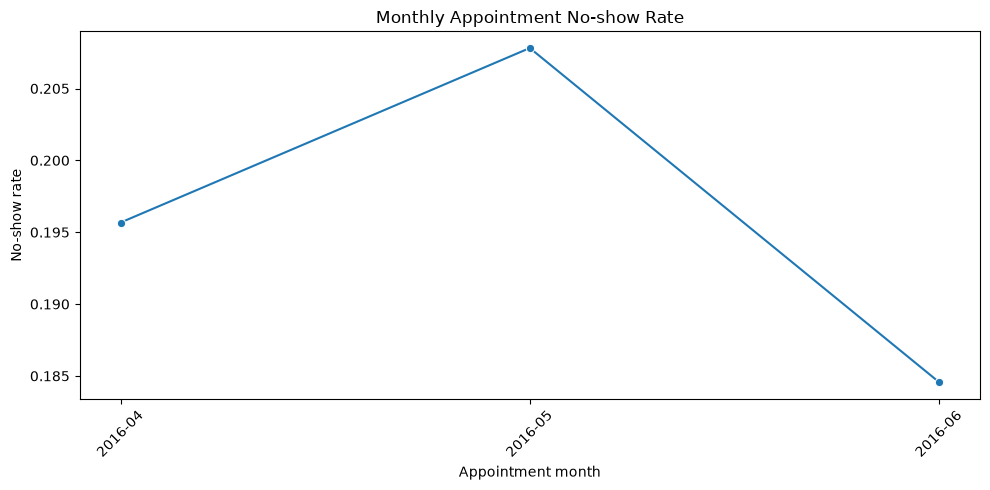

In [8]:
month_summary = (
    df_analysis.groupby("appointment_month")
    .agg(appointments=("AppointmentID", "size"),
         no_show_rate=("no_show", "mean"))
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.lineplot(data=month_summary, x="appointment_month", y="no_show_rate", marker="o")
plt.title("Monthly Appointment No-show Rate")
plt.xlabel("Appointment month")
plt.ylabel("No-show rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Age & Gender

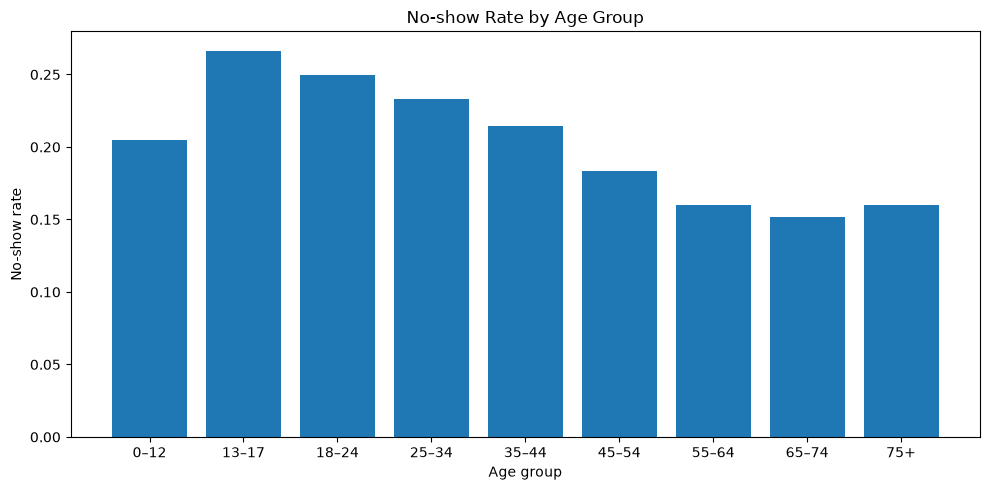

,Gender,appointments,no_show_rate
0,F,71837,20.3%
1,M,38685,20.0%


In [9]:
age_summary = (
    df_analysis.groupby("age_group", observed=False)
    .agg(appointments=("AppointmentID", "size"),
         no_show_rate=("no_show", "mean"))
    .reset_index()
)

plt.figure(figsize=(10, 5))
plt.bar(age_summary["age_group"].astype(str), age_summary["no_show_rate"])
plt.title("No-show Rate by Age Group")
plt.xlabel("Age group")
plt.ylabel("No-show rate")
plt.tight_layout()
plt.show()

gender_summary = (
    df_analysis.groupby("Gender")
    .agg(appointments=("AppointmentID", "size"),
         no_show_rate=("no_show", "mean"))
    .reset_index()
)

display(gender_summary.assign(
    no_show_rate=gender_summary["no_show_rate"].map(lambda x: f"{x:.1%}")
))

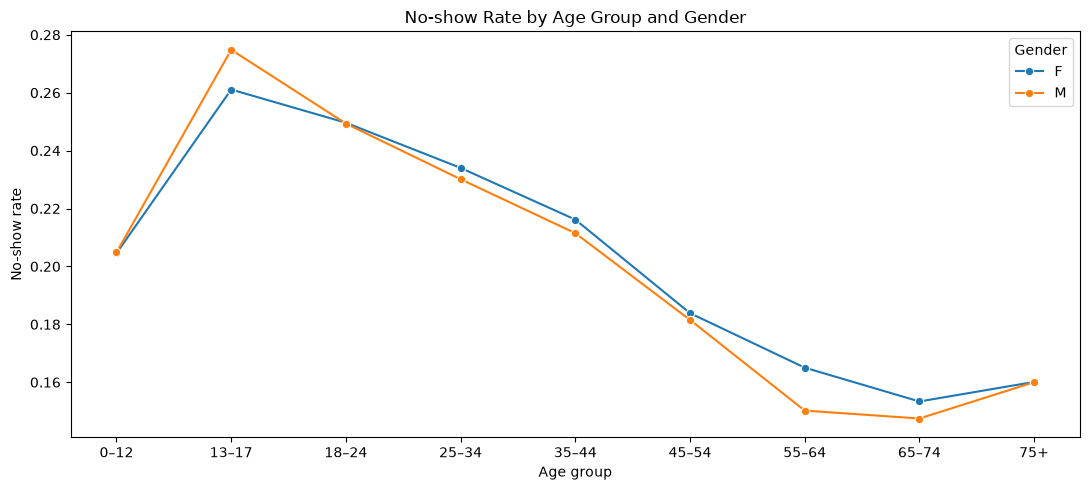

In [10]:
age_gender = (
    df_analysis.groupby(["age_group", "Gender"], observed=False)
    .agg(appointments=("AppointmentID", "size"),
         no_show_rate=("no_show", "mean"))
    .reset_index()
)

plt.figure(figsize=(11, 5))
sns.lineplot(data=age_gender, x="age_group", y="no_show_rate",
             hue="Gender", marker="o")
plt.title("No-show Rate by Age Group and Gender")
plt.xlabel("Age group")
plt.ylabel("No-show rate")
plt.tight_layout()
plt.show()

## 8. SMS Reminder Analysis — Interpreted Carefully

In [11]:
sms_summary = (
    df_analysis.groupby("SMS_received")
    .agg(appointments=("AppointmentID", "size"),
         no_show_rate=("no_show", "mean"))
    .reset_index()
)

sms_summary["sms_status"] = sms_summary["SMS_received"].map({
    0: "No SMS", 1: "SMS received"
})

display(sms_summary[["sms_status", "appointments", "no_show_rate"]].assign(
    no_show_rate=lambda x: x["no_show_rate"].map(lambda v: f"{v:.1%}")
))

,sms_status,appointments,no_show_rate
0,No SMS,75040,16.7%
1,SMS received,35482,27.6%


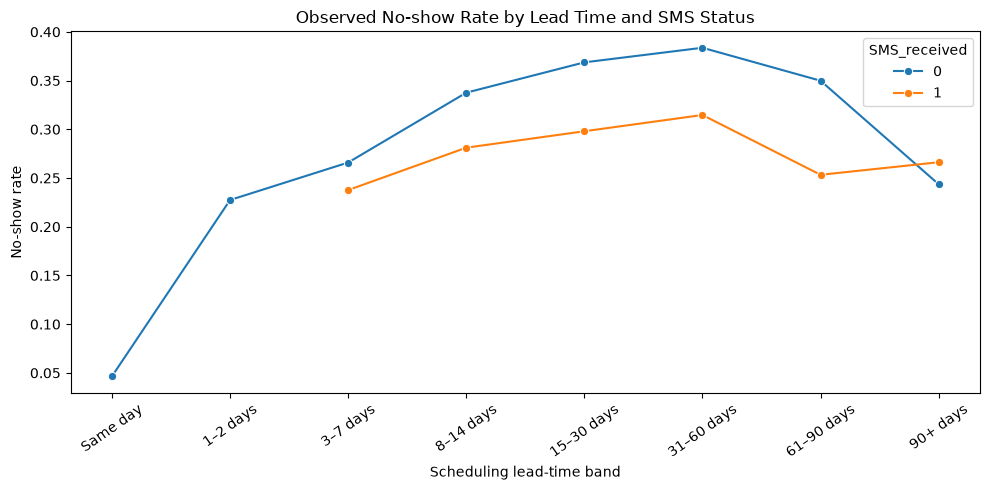

In [12]:
sms_lead = (
    df_analysis.groupby(["lead_time_band", "SMS_received"], observed=False)
    .agg(appointments=("AppointmentID", "size"),
         no_show_rate=("no_show", "mean"))
    .reset_index()
)

plt.figure(figsize=(10, 5))
sns.lineplot(data=sms_lead, x="lead_time_band", y="no_show_rate",
             hue="SMS_received", marker="o")
plt.title("Observed No-show Rate by Lead Time and SMS Status")
plt.xlabel("Scheduling lead-time band")
plt.ylabel("No-show rate")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

### Interpretation

The raw SMS groups have different no-show rates, but that does **not** mean SMS causes missed appointments. Reminder assignment is not random, and SMS receipt is related to appointment characteristics such as lead time.

Therefore, the appropriate conclusion is that SMS status is **associated with** different observed outcomes. A real intervention decision would require controlled testing or stronger causal methods.

## 9. Health & Social Characteristics

In [13]:
health_specs = {
    "Scholarship": "Scholarship",
    "Hipertension": "Hypertension",
    "Diabetes": "Diabetes",
    "Alcoholism": "Alcoholism",
    "Handcap": "Handicap"
}

rows = []
for col, label in health_specs.items():
    temp = df_analysis.groupby(col)["no_show"].agg(["count", "mean"]).reset_index()
    for _, row in temp.iterrows():
        rows.append([label, row[col], int(row["count"]), row["mean"]])

health_summary = pd.DataFrame(
    rows, columns=["Factor", "Value", "Appointments", "No_show_rate"]
)
display(health_summary.assign(
    no_show_rate=health_summary["No_show_rate"].map(lambda x: f"{x:.1%}")
))

,Factor,Value,Appointments,No_show_rate,no_show_rate
0,Scholarship,0.00,99661,0.20,19.8%
1,Scholarship,1.00,10861,0.24,23.7%
2,Hypertension,0.00,88721,0.21,20.9%
3,Hypertension,1.00,21801,0.17,17.3%
4,Diabetes,0.00,102579,0.20,20.4%
5,Diabetes,1.00,7943,0.18,18.0%
6,Alcoholism,0.00,107162,0.20,20.2%
7,Alcoholism,1.00,3360,0.20,20.1%
8,Handicap,0.00,108283,0.20,20.2%
9,Handicap,1.00,2040,0.18,17.8%


## 10. Neighbourhood Analysis

In [14]:
neighbourhood_summary = (
    df_analysis.groupby("Neighbourhood")
    .agg(appointments=("AppointmentID", "size"),
         no_show_rate=("no_show", "mean"))
    .query("appointments >= 100")
    .sort_values("no_show_rate", ascending=False)
)

top_neighbourhoods = neighbourhood_summary.head(10).reset_index()

display(top_neighbourhoods.assign(
    no_show_rate=top_neighbourhoods["no_show_rate"].map(lambda x: f"{x:.1%}")
))

,Neighbourhood,appointments,no_show_rate
0,SANTOS DUMONT,1276,28.9%
1,SANTA CECÍLIA,448,27.5%
2,SANTA CLARA,506,26.5%
3,ITARARÉ,3514,26.3%
4,JESUS DE NAZARETH,2853,24.4%
5,HORTO,175,24.0%
6,ILHA DO PRÍNCIPE,2266,23.5%
7,CARATOÍRA,2565,23.0%
8,ANDORINHAS,2262,23.0%
9,PRAIA DO SUÁ,1288,22.8%


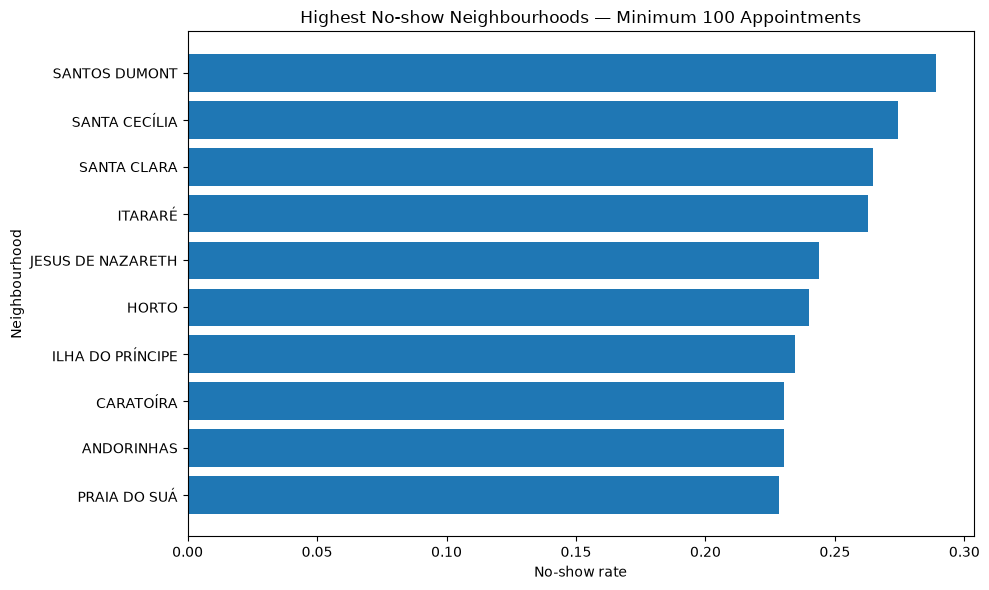

In [15]:
plot_df = top_neighbourhoods.sort_values("no_show_rate")
plt.figure(figsize=(10, 6))
plt.barh(plot_df["Neighbourhood"].astype(str), plot_df["no_show_rate"])
plt.title("Highest No-show Neighbourhoods — Minimum 100 Appointments")
plt.xlabel("No-show rate")
plt.ylabel("Neighbourhood")
plt.tight_layout()
plt.show()

A minimum-volume threshold is used because very small neighbourhood groups can produce extreme rates from only a few appointments. High no-show rates should therefore be interpreted together with appointment volume.

## 11. Repeat-Patient Behaviour

In [16]:
repeat_summary = (
    df_analysis.groupby("repeat_patient")
    .agg(appointments=("AppointmentID", "size"),
         no_show_rate=("no_show", "mean"))
    .reset_index()
)

repeat_summary["patient_type"] = repeat_summary["repeat_patient"].map({
    False: "One-time patient in dataset",
    True: "Repeat patient in dataset"
})

display(repeat_summary[["patient_type", "appointments", "no_show_rate"]].assign(
    no_show_rate=lambda x: x["no_show_rate"].map(lambda v: f"{v:.1%}")
))

,patient_type,appointments,no_show_rate
0,One-time patient in dataset,37920,18.8%
1,Repeat patient in dataset,72602,20.9%


## 12. Patient Appointment History

In [17]:
history_summary = (
    df_analysis.groupby("patient_total_appointments")
    .agg(appointments=("AppointmentID", "size"),
         no_show_rate=("no_show", "mean"))
    .reset_index()
)

display(history_summary.head(15).assign(
    no_show_rate=lambda x: x["no_show_rate"].map(lambda v: f"{v:.1%}")
))

,patient_total_appointments,appointments,no_show_rate
0,1,37920,18.8%
1,2,27789,20.7%
2,3,16499,20.9%
3,4,9468,22.2%
4,5,5593,21.2%
5,6,3318,22.0%
6,7,2142,23.6%
7,8,1615,22.8%
8,9,936,22.6%
9,10,850,19.6%


## 13. SQLite Analytical Layer

In [18]:
sql_df = df_analysis.copy()
for col in ["ScheduledDay", "AppointmentDay"]:
    sql_df[col] = sql_df[col].astype(str)

conn = sqlite3.connect(SQLITE_PATH)
sql_df.to_sql("appointments", conn, if_exists="replace", index=False)

display(pd.read_sql_query(
    "SELECT COUNT(*) AS appointment_rows, COUNT(DISTINCT PatientId) AS unique_patients FROM appointments",
    conn
))

,appointment_rows,unique_patients
0,110522,62299


### SQL question 1 — Which lead-time bands have the highest no-show rates?

In [19]:
sql_lead = pd.read_sql_query('''
SELECT lead_time_band,
       COUNT(*) AS appointments,
       AVG(no_show) AS no_show_rate
FROM appointments
GROUP BY lead_time_band
ORDER BY no_show_rate DESC
''', conn)

display(sql_lead.assign(
    no_show_rate=sql_lead["no_show_rate"].map(lambda x: f"{x:.1%}")
))

,lead_time_band,appointments,no_show_rate
0,31–60 days,8283,34.2%
1,15–30 days,17371,32.6%
2,8–14 days,12025,30.5%
3,61–90 days,1878,28.8%
4,90+ days,217,25.8%
5,3–7 days,20247,25.0%
6,1–2 days,11938,22.7%
7,Same day,38563,4.6%


### SQL question 2 — No-show rate by appointment weekday and SMS status

In [20]:
sql_weekday_sms = pd.read_sql_query('''
SELECT appointment_weekday,
       SMS_received,
       COUNT(*) AS appointments,
       AVG(no_show) AS no_show_rate
FROM appointments
GROUP BY appointment_weekday, SMS_received
ORDER BY no_show_rate DESC
''', conn)

display(sql_weekday_sms.assign(
    no_show_rate=sql_weekday_sms["no_show_rate"].map(lambda x: f"{x:.1%}")
))

,appointment_weekday,SMS_received,appointments,no_show_rate
0,Thursday,1,4847,28.4%
1,Tuesday,1,10408,27.9%
2,Monday,1,7144,27.3%
3,Friday,1,4210,27.2%
4,Wednesday,1,8860,27.2%
5,Saturday,0,26,23.1%
6,Saturday,1,13,23.1%
7,Friday,0,14809,19.5%
8,Monday,0,15570,17.6%
9,Thursday,0,12399,15.8%


### SQL question 3 — High-volume neighbourhoods

In [21]:
sql_neighbourhood = pd.read_sql_query('''
SELECT Neighbourhood,
       COUNT(*) AS appointments,
       AVG(no_show) AS no_show_rate
FROM appointments
GROUP BY Neighbourhood
HAVING COUNT(*) >= 500
ORDER BY no_show_rate DESC
LIMIT 15
''', conn)

display(sql_neighbourhood.assign(
    no_show_rate=sql_neighbourhood["no_show_rate"].map(lambda x: f"{x:.1%}")
))

,Neighbourhood,appointments,no_show_rate
0,SANTOS DUMONT,1276,28.9%
1,SANTA CLARA,506,26.5%
2,ITARARÉ,3514,26.3%
3,JESUS DE NAZARETH,2853,24.4%
4,ILHA DO PRÍNCIPE,2266,23.5%
5,CARATOÍRA,2565,23.0%
6,ANDORINHAS,2262,23.0%
7,PRAIA DO SUÁ,1288,22.8%
8,GURIGICA,2018,22.6%
9,BENTO FERREIRA,858,22.5%


## 14. Operational Risk Segmentation

In [22]:
risk_segment = (
    df_analysis.groupby(["lead_time_band", "SMS_received"], observed=True)
    .agg(appointments=("AppointmentID", "size"),
         no_show_rate=("no_show", "mean"))
    .reset_index()
)

risk_segment["sms_status"] = risk_segment["SMS_received"].map({
    0: "No SMS", 1: "SMS received"
})
risk_segment["estimated_no_shows"] = (
    risk_segment["appointments"] * risk_segment["no_show_rate"]
).round().fillna(0).astype(int)

display(risk_segment.sort_values("no_show_rate", ascending=False).head(12).assign(
    no_show_rate=lambda x: x["no_show_rate"].map(lambda v: f"{v:.1%}")
))

,lead_time_band,SMS_received,appointments,no_show_rate,sms_status,estimated_no_shows
8,31–60 days,0,3224,38.4%,No SMS,1237
6,15–30 days,0,6851,36.9%,No SMS,2526
10,61–90 days,0,666,35.0%,No SMS,233
4,8–14 days,0,5021,33.8%,No SMS,1695
9,31–60 days,1,5059,31.5%,SMS received,1592
7,15–30 days,1,10520,29.8%,SMS received,3135
5,8–14 days,1,7004,28.1%,SMS received,1969
13,90+ days,1,139,26.6%,SMS received,37
2,3–7 days,0,8699,26.6%,No SMS,2313
11,61–90 days,1,1212,25.3%,SMS received,307


## 15. Key Findings

### 1. No-shows are a meaningful operational issue
About **one in five analysed appointments** is a no-show.

### 2. Scheduling lead time is strongly associated with attendance
Same-day appointments have a much lower observed no-show rate, while several multi-week lead-time bands have materially higher rates.

### 3. Younger groups show higher observed no-show rates
The age pattern is not perfectly linear, so age is better treated as a segmentation variable than as a simple increasing/decreasing driver.

### 4. SMS results require context
The raw SMS group comparison should not be interpreted causally. Reminder assignment is likely related to appointment characteristics.

### 5. Neighbourhood performance varies
There are meaningful differences across neighbourhoods, but low-volume areas can be statistically unstable, so operational prioritization should use both rate and volume.

### 6. Patient history adds useful context
Patients with repeated appointments can have different observed attendance patterns from one-time patients, which suggests that historical behaviour can be useful in operational segmentation.

## 16. Recommendations

### 1. Prioritize long-lead appointments
Use additional confirmation workflows for appointments scheduled several weeks ahead.

### 2. Re-evaluate reminder strategy
Do not simply increase SMS volume. Test reminder timing, confirmation links, alternative channels, and escalation workflows.

### 3. Use risk-based follow-up
Prioritize staff outreach using combinations of lead time, patient history, and appointment characteristics instead of treating every appointment identically.

### 4. Monitor high-volume neighbourhoods
Build a recurring dashboard that reports both appointment volume and no-show rate.

### 5. Reconfirm appointments close to the visit
The large attendance difference between same-day and longer-lead appointments supports testing a confirmation workflow closer to the appointment date.

### 6. Measure interventions
If a new reminder or scheduling policy is introduced, compare outcomes before and after implementation or use controlled testing where appropriate. This is necessary to determine whether the intervention actually reduces no-shows.

## 17. Limitations

- This is observational data; associations do not establish causation.
- SMS assignment is not random, so raw SMS comparisons can be confounded.
- `Age = -1` is invalid and is treated as missing.
- Five records have negative scheduling lead time and are excluded from lead-time analysis.
- Repeated appointments from the same patient mean appointment observations are not fully independent.
- Neighbourhood rates can be unstable for low-volume groups.
- No monetary cost per missed appointment is provided, so financial impact cannot be calculated reliably.
- The dataset does not provide a complete clinical or operational explanation for why appointments were missed.

## 18. Final Conclusion

The analysis shows that missed appointments are not evenly distributed across the appointment population. **Scheduling lead time, age group, appointment weekday, neighbourhood, patient history, and other characteristics show meaningful differences in observed no-show rates.**

The strongest operational opportunity is to focus attention on appointments scheduled well in advance and to design reminder and confirmation workflows around observable risk patterns.

The key analytical principle is to distinguish **association from causation**. A segment with a higher observed no-show rate is not automatically the cause of missed appointments. Operational interventions should therefore be tested and measured rather than assumed to work.

In [23]:
final_summary = pd.DataFrame({
    "Metric": [
        "Appointments analysed", "Unique patients", "No-show appointments",
        "No-show rate", "SMS coverage", "Median lead time (days)",
        "Neighbourhoods represented"
    ],
    "Value": [
        f"{len(df_analysis):,}",
        f"{df_analysis['PatientId'].nunique():,}",
        f"{df_analysis['no_show'].sum():,}",
        f"{df_analysis['no_show'].mean():.1%}",
        f"{df_analysis['SMS_received'].mean():.1%}",
        f"{df_analysis['waiting_days'].median():.0f}",
        f"{df_analysis['Neighbourhood'].nunique():,}"
    ]
})
display(final_summary)

conn.close()
print("SQLite database:", SQLITE_PATH)
print("Analysis complete.")

,Metric,Value
0,Appointments analysed,"110,522"
1,Unique patients,"62,299"
2,No-show appointments,"22,314"
3,No-show rate,20.2%
4,SMS coverage,32.1%
5,Median lead time (days),4
6,Neighbourhoods represented,81


SQLite database: hospital_appointments.sqlite
Analysis complete.
